In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression


from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
     accuracy_score,
     confusion_matrix,
     classification_report,
     roc_auc_score
)



In [6]:
#import data
df = pd.read_csv("netflix_titles.csv")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [7]:
df.info()

df.describe()

df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [8]:
#Check dataset size
df.shape

#check column
df.columns

#check duplicate records
df.duplicated().sum()

#Check unique values in important columns
print("Content Types:", df["type"].unique())

print("Ratings:", df["rating"].unique())

print("Number of Countries:", df["country"].nunique())


Content Types: <ArrowStringArray>
['Movie', 'TV Show']
Length: 2, dtype: str
Ratings: <ArrowStringArray>
[   'PG-13',    'TV-MA',       'PG',    'TV-14',    'TV-PG',     'TV-Y',
    'TV-Y7',        'R',     'TV-G',        'G',    'NC-17',   '74 min',
   '84 min',   '66 min',       'NR',        nan, 'TV-Y7-FV',       'UR']
Length: 18, dtype: str
Number of Countries: 748


In [9]:
df[df["rating"].str.contains("min", na=False)]
df[df["rating"].str.contains("min", na=False)][
    ["title", "type", "rating", "duration"]
]
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Duplicate records:
0


In [10]:
df.duplicated().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_report[missing_report["Missing Values"] > 0]
df[df["rating"].isnull()][["title", "type", "rating", "duration"]]
df[df["duration"].isnull()][["title", "type", "rating", "duration"]]


,title,type,rating,duration
5541,Louis C.K. 2017,Movie,74 min,NaN
5794,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN


In [11]:
mask = df["rating"].str.contains("min", na=False)

df.loc[mask, "duration"] = df.loc[mask, "rating"]

df.loc[mask, "rating"] = np.nan

df.loc[mask, ["title", "type", "rating", "duration"]]
print("Missing ratings:", df["rating"].isnull().sum())
print("Missing durations:", df["duration"].isnull().sum())

Missing ratings: 7
Missing durations: 0


In [12]:

# ==========================================
# PHASE 3: DATA CLEANING
# Netflix Movies & TV Shows Analysis
# ==========================================

# 1. Create a copy of the original dataset
# This keeps our original data safe.
df_clean = df.copy()


# 2. Handle missing values in text columns
# Replace missing director, cast and country
# information with "Not Available".
text_columns = ["director", "cast", "country"]

for column in text_columns:
    df_clean[column] = df_clean[column].fillna("Not Available")


# 3. Handle missing values in rating
# Use "Not Rated" instead of deleting these records.
df_clean["rating"] = df_clean["rating"].fillna("Not Rated")


# 4. Handle missing values in date_added
# Use "Not Available" where the date is missing.
df_clean["date_added"] = df_clean["date_added"].fillna("Not Available")


# 5. Check for duplicate records
# Remove duplicates only if any are found.
df_clean = df_clean.drop_duplicates()


# 6. Standardize date_added column
# Convert date_added into proper datetime format.
# Invalid or unavailable dates will become NaT.
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"],
    format="mixed",
    errors="coerce"
)


# 7. Verify the cleaned dataset
print("DATA CLEANING COMPLETED!")
print("----------------------------------")

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate records:", df_clean.duplicated().sum())

# 8. Display the cleaned dataset
df_clean.head()


DATA CLEANING COMPLETED!
----------------------------------
Original dataset shape: (8807, 12)
Cleaned dataset shape: (8807, 12)

Remaining missing values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

Duplicate records: 0


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Not Available,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Not Available,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Not Available,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Not Available,Not Available,Not Available,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Not Available,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [14]:
# Save the cleaned dataset for future analysis
df_clean.to_csv(
    "netflix_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [16]:

# ==========================================
# PHASE 4: EXPLORATORY DATA ANALYSIS (EDA)
# Step 1: Basic Dataset Overview
# ==========================================

# Load the cleaned dataset
df_clean = pd.read_csv("netflix_cleaned.csv")

# Calculate basic statistics
total_titles = len(df_clean)

movie_count = (df_clean["type"] == "Movie").sum()

tv_show_count = (df_clean["type"] == "TV Show").sum()

# Calculate percentage distribution
movie_percentage = (movie_count / total_titles) * 100
tv_show_percentage = (tv_show_count / total_titles) * 100

# Display the results
print("NETFLIX CONTENT OVERVIEW")
print("=" * 40)

print("Total Titles:", total_titles)

print("Total Movies:", movie_count)
print("Total TV Shows:", tv_show_count)

print("\nCONTENT DISTRIBUTION")
print("=" * 40)

print(f"Movies: {movie_percentage:.2f}%")
print(f"TV Shows: {tv_show_percentage:.2f}%")


NETFLIX CONTENT OVERVIEW
Total Titles: 8807
Total Movies: 6131
Total TV Shows: 2676

CONTENT DISTRIBUTION
Movies: 69.62%
TV Shows: 30.38%


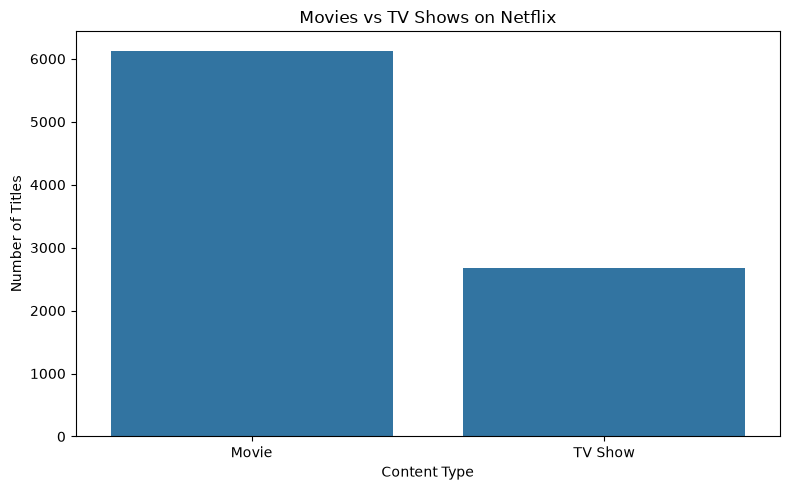

In [17]:

# ==========================================
# Step 2: Movies vs TV Shows Visualization
# ==========================================

# Count the number of titles in each category
content_counts = df_clean["type"].value_counts()

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()


TOP 10 CONTENT RELEASE YEARS
release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64


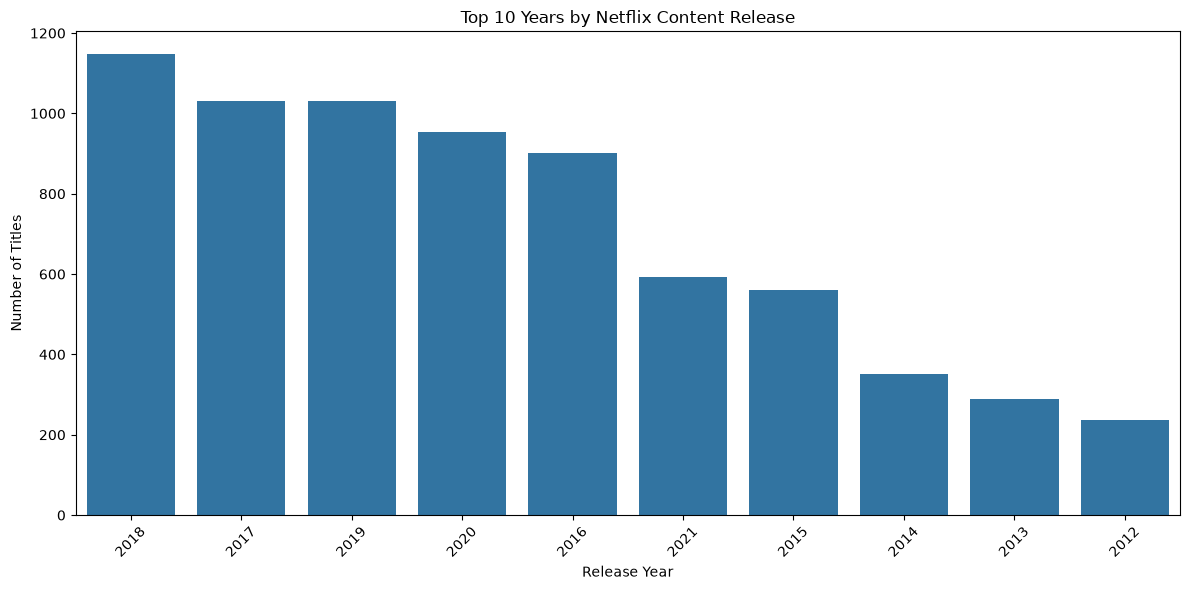

In [18]:

# ==========================================
# EDA - Step 2: Content Release Year Analysis
# ==========================================

# Count the number of titles released each year
release_year_counts = (
    df_clean["release_year"]
    .value_counts()
    .sort_index()
)

# Find the top 10 release years
top_10_years = (
    df_clean["release_year"]
    .value_counts()
    .head(10)
    .sort_values(ascending=False)
)

# Display the results
print("TOP 10 CONTENT RELEASE YEARS")
print("=" * 40)
print(top_10_years)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_years.index.astype(str),
    y=top_10_years.values
)

plt.title("Top 10 Years by Netflix Content Release")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


TOP 10 COUNTRIES PRODUCING NETFLIX CONTENT
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


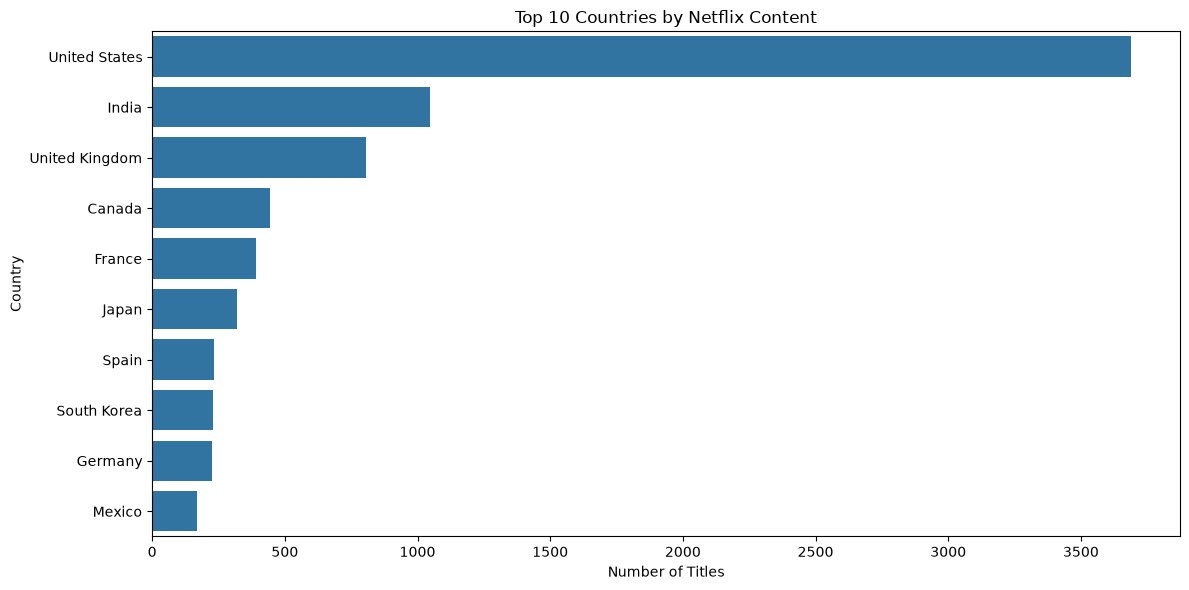

In [19]:

# ==========================================
# EDA - Step 3: Country-wise Content Analysis
# ==========================================

# Select the country column and remove missing placeholders
country_data = df_clean[
    df_clean["country"] != "Not Available"
]["country"]

# Split multiple countries and create a separate row for each country
country_list = country_data.str.split(", ").explode()

# Remove extra spaces
country_list = country_list.str.strip()

# Count the number of titles associated with each country
country_counts = country_list.value_counts()

# Display the top 10 countries
top_10_countries = country_counts.head(10)

print("TOP 10 COUNTRIES PRODUCING NETFLIX CONTENT")
print("=" * 50)
print(top_10_countries)

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index
)

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


TOP 10 NETFLIX GENRES
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


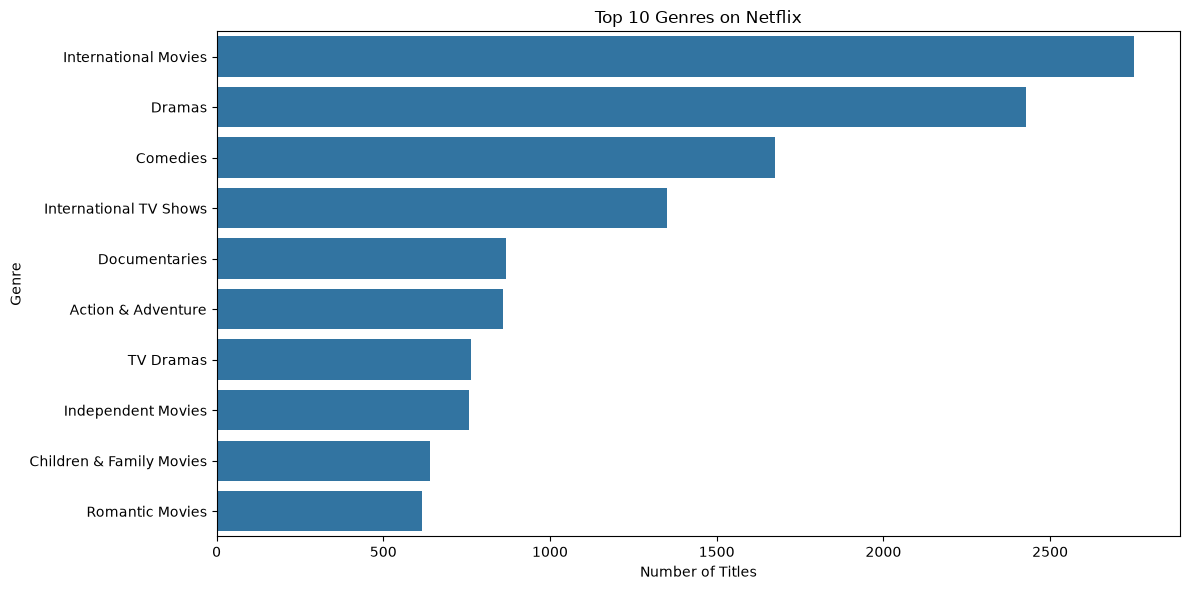

In [20]:

# ==========================================
# EDA - Step 4: Genre Analysis
# ==========================================

# Select the listed_in column and remove missing placeholders
genre_data = df_clean[
    df_clean["listed_in"] != "Not Available"
]["listed_in"]

# Split multiple genres into separate rows
genre_list = genre_data.str.split(", ").explode()

# Remove extra spaces
genre_list = genre_list.str.strip()

# Count the frequency of each genre
genre_counts = genre_list.value_counts()

# Select the top 10 genres
top_10_genres = genre_counts.head(10)

# Display the results
print("TOP 10 NETFLIX GENRES")
print("=" * 40)
print(top_10_genres)

# Create a horizontal bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_genres.values,
    y=top_10_genres.index
)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()


NETFLIX CONTENT RATINGS
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


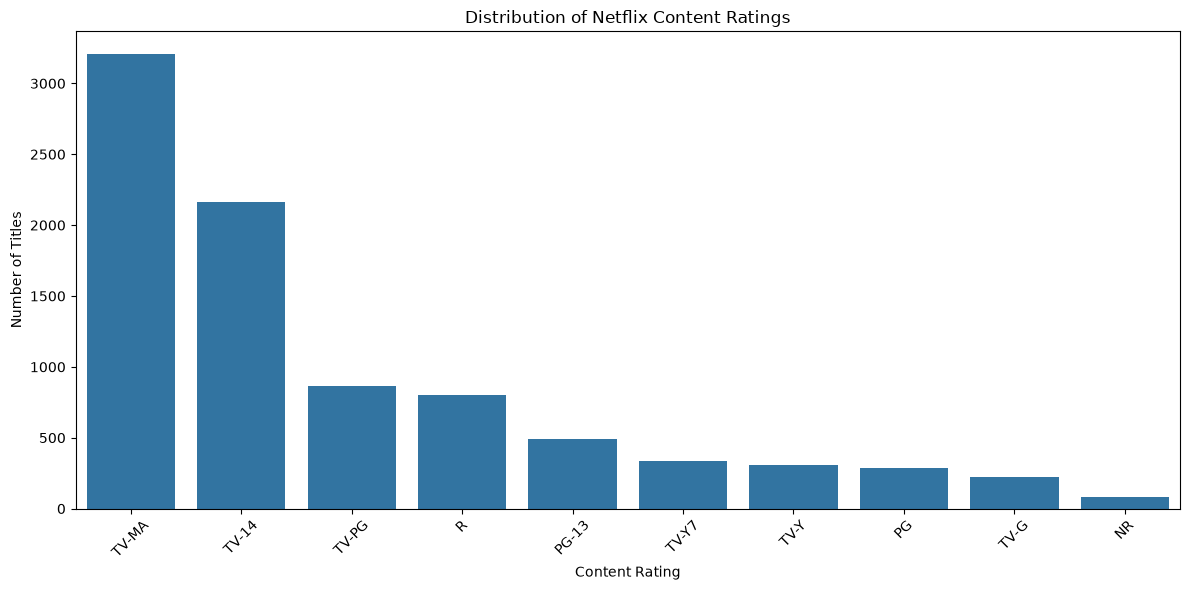

In [21]:

# ==========================================
# EDA - Step 5: Content Rating Analysis
# ==========================================

# Remove unavailable ratings
rating_data = df_clean[
    df_clean["rating"] != "Not Rated"
]["rating"]

# Count the frequency of each rating
rating_counts = rating_data.value_counts()

# Select the top 10 ratings
top_10_ratings = rating_counts.head(10)

# Display the results
print("NETFLIX CONTENT RATINGS")
print("=" * 40)
print(top_10_ratings)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_ratings.index,
    y=top_10_ratings.values
)

plt.title("Distribution of Netflix Content Ratings")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


NETFLIX MOVIE DURATION ANALYSIS
Total Movies: 6131
Average Duration: 99.56 minutes
Median Duration: 98.0 minutes
Shortest Movie: 3.0 minutes
Longest Movie: 312.0 minutes


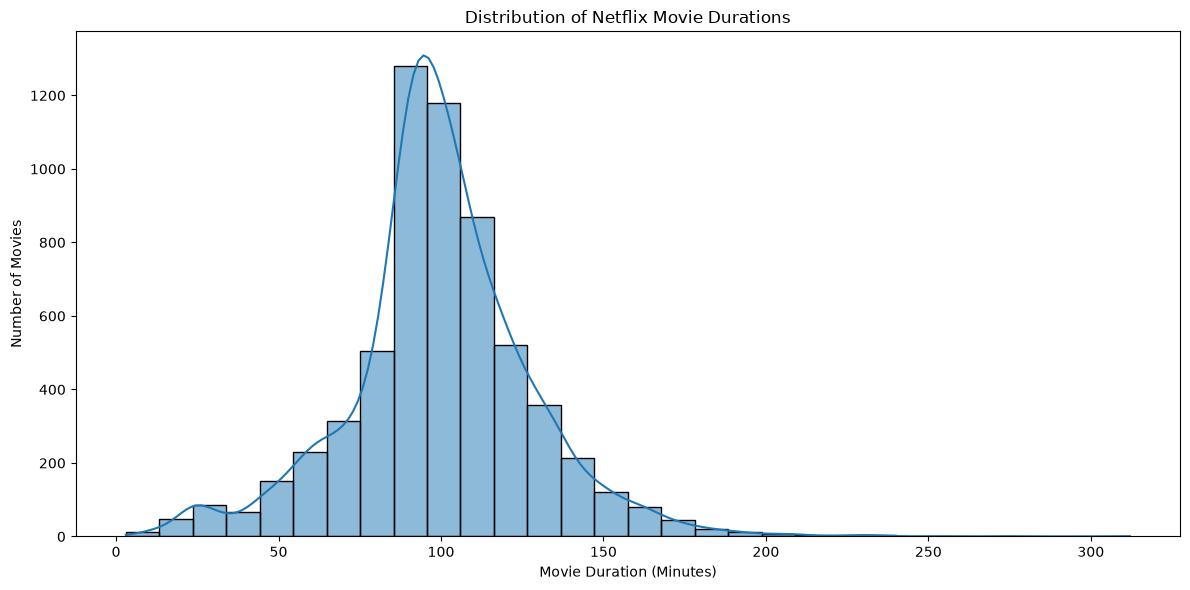

In [22]:

# ==========================================
# EDA - Step 6: Movie Duration Analysis
# ==========================================

# Select only Movie records
movies = df_clean[df_clean["type"] == "Movie"].copy()

# Extract numerical duration from values like "120 min"
movies["duration_minutes"] = (
    movies["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)

# Calculate duration statistics
print("NETFLIX MOVIE DURATION ANALYSIS")
print("=" * 45)

print("Total Movies:", len(movies))
print("Average Duration:", round(movies["duration_minutes"].mean(), 2), "minutes")
print("Median Duration:", movies["duration_minutes"].median(), "minutes")
print("Shortest Movie:", movies["duration_minutes"].min(), "minutes")
print("Longest Movie:", movies["duration_minutes"].max(), "minutes")

# Create a histogram to show movie duration distribution
plt.figure(figsize=(12, 6))

sns.histplot(
    data=movies,
    x="duration_minutes",
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Movie Duration (Minutes)")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()


NETFLIX TV SHOW SEASON ANALYSIS
Total TV Shows: 2676
Average Seasons: 1.76
Median Seasons: 1.0
Maximum Seasons: 17.0

TV SHOW SEASON DISTRIBUTION
season_count
1.0     1793
2.0      425
3.0      199
4.0       95
5.0       65
6.0       33
7.0       23
8.0       17
9.0        9
10.0       7
11.0       2
12.0       2
13.0       3
15.0       2
17.0       1
Name: count, dtype: int64


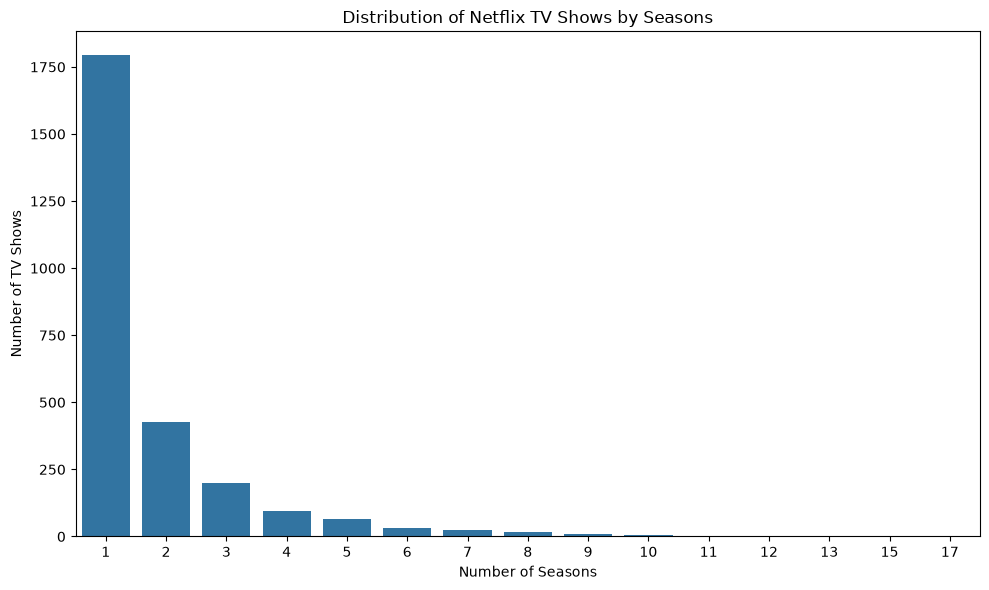

In [23]:

# ==========================================
# EDA - Step 7: TV Show Season Analysis
# ==========================================

# Select only TV Show records
tv_shows = df_clean[df_clean["type"] == "TV Show"].copy()

# Extract numerical season count from duration
# Example: "3 Seasons" becomes 3
tv_shows["season_count"] = (
    tv_shows["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)

# Calculate season statistics
print("NETFLIX TV SHOW SEASON ANALYSIS")
print("=" * 45)

print("Total TV Shows:", len(tv_shows))

print(
    "Average Seasons:",
    round(tv_shows["season_count"].mean(), 2)
)

print(
    "Median Seasons:",
    tv_shows["season_count"].median()
)

print(
    "Maximum Seasons:",
    tv_shows["season_count"].max()
)

# Count TV Shows by number of seasons
season_distribution = tv_shows["season_count"].value_counts().sort_index()

print("\nTV SHOW SEASON DISTRIBUTION")
print(season_distribution)

# Create a bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=season_distribution.index.astype(int),
    y=season_distribution.values
)

plt.title("Distribution of Netflix TV Shows by Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")

plt.tight_layout()
plt.show()


NETFLIX YEARLY CONTENT ADDITIONS
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64

Year with maximum content additions:
2019.0
Number of titles added:
2016


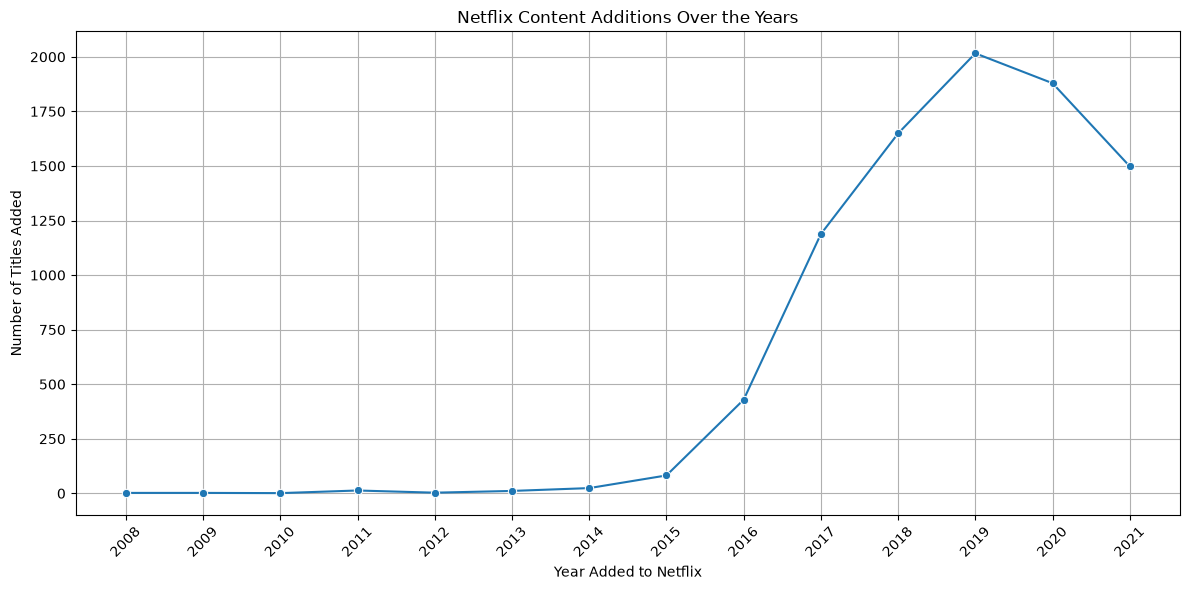

In [24]:

# ==========================================
# EDA - Step 8: Netflix Content Addition Trends
# ==========================================

# Create a copy of the cleaned dataset
date_analysis = df_clean.copy()

# Convert date_added into datetime format
date_analysis["date_added"] = pd.to_datetime(
    date_analysis["date_added"],
    errors="coerce"
)

# Extract year and month from date_added
date_analysis["year_added"] = date_analysis["date_added"].dt.year

date_analysis["month_added"] = date_analysis["date_added"].dt.month

# Count titles added each year
yearly_additions = date_analysis["year_added"].value_counts().sort_index()

# Display yearly content additions
print("NETFLIX YEARLY CONTENT ADDITIONS")
print("=" * 45)
print(yearly_additions)

# Identify the year with the highest number of additions
print("\nYear with maximum content additions:")
print(yearly_additions.idxmax())

print("Number of titles added:")
print(yearly_additions.max())

# Create a line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=yearly_additions.index,
    y=yearly_additions.values,
    marker="o"
)

plt.title("Netflix Content Additions Over the Years")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles Added")

plt.xticks(yearly_additions.index, rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


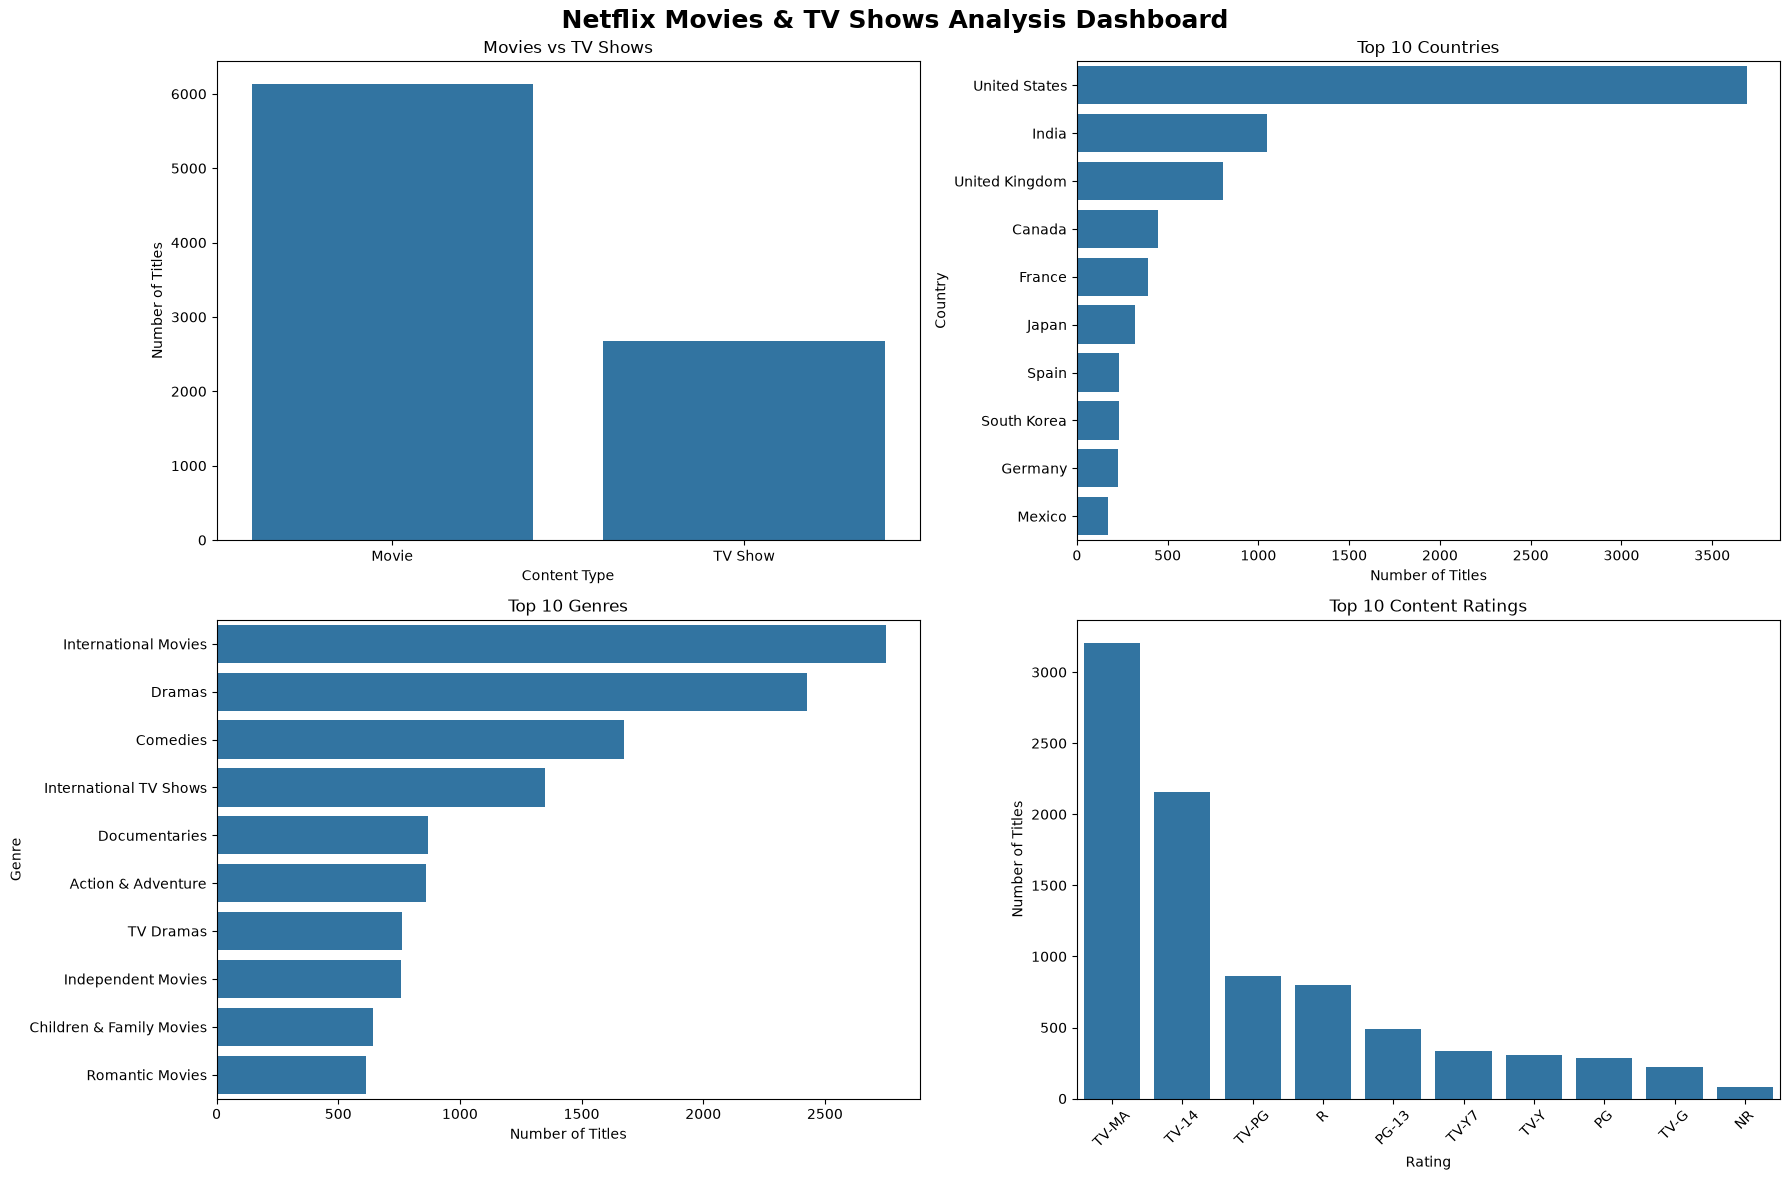

In [25]:

# ==========================================
# PHASE 5: DATA VISUALIZATION
# Netflix Analysis Dashboard
# ==========================================

# Create a 2x2 dashboard layout
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# ------------------------------------------
# Chart 1: Movies vs TV Shows
# ------------------------------------------

content_counts = df_clean["type"].value_counts()

sns.barplot(
    x=content_counts.index,
    y=content_counts.values,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Movies vs TV Shows")
axes[0, 0].set_xlabel("Content Type")
axes[0, 0].set_ylabel("Number of Titles")


# ------------------------------------------
# Chart 2: Top 10 Countries
# ------------------------------------------

country_data = df_clean[
    df_clean["country"] != "Not Available"
]["country"]

country_counts = (
    country_data.str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Top 10 Countries")
axes[0, 1].set_xlabel("Number of Titles")
axes[0, 1].set_ylabel("Country")


# ------------------------------------------
# Chart 3: Top 10 Genres
# ------------------------------------------

genre_data = df_clean["listed_in"]

genre_counts = (
    genre_data.str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Top 10 Genres")
axes[1, 0].set_xlabel("Number of Titles")
axes[1, 0].set_ylabel("Genre")


# ------------------------------------------
# Chart 4: Content Ratings
# ------------------------------------------

rating_counts = (
    df_clean[df_clean["rating"] != "Not Rated"]["rating"]
    .value_counts()
    .head(10)
)

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Top 10 Content Ratings")
axes[1, 1].set_xlabel("Rating")
axes[1, 1].set_ylabel("Number of Titles")

# Rotate rating labels for readability
axes[1, 1].tick_params(axis="x", rotation=45)


# ------------------------------------------
# Final Dashboard Formatting
# ------------------------------------------

plt.suptitle(
    "Netflix Movies & TV Shows Analysis Dashboard",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [27]:
plt.savefig(
    "netflix_analysis_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [28]:

# ==========================================
# PHASE 6: BUSINESS INSIGHTS
# Netflix Movies & TV Shows Analysis
# ==========================================

# 1. Total content analysis
total_titles = len(df_clean)

movie_count = (df_clean["type"] == "Movie").sum()
tv_show_count = (df_clean["type"] == "TV Show").sum()

# 2. Content distribution
movie_percentage = movie_count / total_titles * 100
tv_percentage = tv_show_count / total_titles * 100

# 3. Top countries
country_counts = (
    df_clean[df_clean["country"] != "Not Available"]["country"]
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
)

# 4. Top genres
genre_counts = (
    df_clean["listed_in"]
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
)

# 5. Top ratings
rating_counts = (
    df_clean[df_clean["rating"] != "Not Rated"]["rating"]
    .value_counts()
)

# 6. Movie duration
movies = df_clean[df_clean["type"] == "Movie"].copy()

movie_durations = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# 7. TV Show seasons
tv_shows = df_clean[df_clean["type"] == "TV Show"].copy()

tv_seasons = pd.to_numeric(
    tv_shows["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# 8. Display business insights
print("=" * 55)
print("       NETFLIX BUSINESS INSIGHTS REPORT")
print("=" * 55)

print("\n1. TOTAL CONTENT")
print("Total Titles:", total_titles)

print("\n2. CONTENT DISTRIBUTION")
print(f"Movies: {movie_count} ({movie_percentage:.2f}%)")
print(f"TV Shows: {tv_show_count} ({tv_percentage:.2f}%)")

print("\n3. TOP 5 COUNTRIES")
print(country_counts.head(5))

print("\n4. TOP 5 GENRES")
print(genre_counts.head(5))

print("\n5. TOP 5 CONTENT RATINGS")
print(rating_counts.head(5))

print("\n6. MOVIE DURATION")
print("Average Duration:", round(movie_durations.mean(), 2), "minutes")
print("Median Duration:", movie_durations.median(), "minutes")

print("\n7. TV SHOW SEASONS")
print("Average Seasons:", round(tv_seasons.mean(), 2))
print("Median Seasons:", tv_seasons.median())

print("\n" + "=" * 55)
print("             REPORT COMPLETED")
print("=" * 55)


       NETFLIX BUSINESS INSIGHTS REPORT

1. TOTAL CONTENT
Total Titles: 8807

2. CONTENT DISTRIBUTION
Movies: 6131 (69.62%)
TV Shows: 2676 (30.38%)

3. TOP 5 COUNTRIES
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Name: count, dtype: int64

4. TOP 5 GENRES
listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

5. TOP 5 CONTENT RATINGS
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
Name: count, dtype: int64

6. MOVIE DURATION
Average Duration: 99.56 minutes
Median Duration: 98.0 minutes

7. TV SHOW SEASONS
Average Seasons: 1.76
Median Seasons: 1.0

             REPORT COMPLETED
